# Exploring variation in cancer cell-line drug responses

## Objective
Understand the structure, coverage, and quality of the PRISM primary-screen
drug-response data before selecting a prediction task.

## Experimental unit
Each measurement describes the response of one cancer cell line to one
treatment condition. The response table stores cell lines as rows and
treatments as columns.

## Outcome
The outcome is a processed log-fold-change viability measurement relative
to controls. More negative values indicate lower relative viability signal.
These laboratory measurements do not establish clinical treatment efficacy.

## Initial questions
1. Did the response matrix load correctly?
2. Are cell-line and treatment identifiers unique?
3. How much data is missing, and where is missingness concentrated?
4. How do responses vary across cell lines and treatments?


Initial import of files and understanding of structure and descriptive statistics

In [18]:
import pandas as pd
import numpy as np
responses = pd.read_csv('../data/raw/primary-screen-replicate-collapsed-logfold-change.csv')
responses.head()

,Unnamed: 0,BRD-A00077618-236-07-6::2.5::HTS,BRD-A00100033-001-08-9::2.5::HTS,BRD-A00147595-001-01-5::2.5::HTS,BRD-A00218260-001-03-4::2.5::HTS,BRD-A00376169-001-01-6::2.5::HTS,BRD-A00520476-001-07-4::2.5::HTS,BRD-A00546892-001-02-6::2.5::HTS,BRD-A00578795-001-04-3::2.5::HTS,BRD-A00758722-001-04-9::2.5::HTS,...,BRD-K98557884-001-01-6::2.5::MTS004,BRD-K99077012-001-01-9::2.332734192::MTS004,BRD-K99199077-001-16-1::2.603211317::MTS004,BRD-K99431849-001-01-7::2.500018158::MTS004,BRD-K99447003-335-04-1::2.37737659::MTS004,BRD-K99506538-001-03-8::2.5::MTS004,BRD-K99616396-001-05-1::2.499991421::MTS004,BRD-K99879819-001-02-1::2.5187366::MTS004,BRD-K99919177-001-01-3::2.5::MTS004,BRD-M63173034-001-03-6::2.64076472::MTS004
0,ACH-000001,-0.015577,-0.449332,0.489379,0.206675,0.272730,0.021036,-0.025460,0.467158,-0.736306,...,0.429238,0.204841,0.150055,-0.575404,-0.101247,0.399233,-0.127658,-0.141651,-1.153652,0.510464
1,ACH-000007,-0.095730,0.257943,0.772349,-0.438502,-0.732832,0.779201,0.426523,-1.288508,-0.476133,...,-0.471486,0.212998,-0.123230,0.625527,0.383198,0.212031,0.349225,-0.387439,-0.831461,0.323558
2,ACH-000008,0.379480,-0.596132,0.548056,0.422269,-0.216986,0.081866,0.145335,-0.570841,-0.512119,...,-0.111951,0.534787,0.206642,-0.410153,-0.560722,-0.036088,0.158071,0.171043,-3.947090,0.099310
3,ACH-000010_FAILED_STR,0.118890,-0.231615,0.621937,-0.202707,-1.005139,-0.213739,0.020246,-0.795278,NaN,...,0.200605,-0.075356,0.610310,-0.019413,-0.202971,0.218158,-0.411009,-0.181540,-3.010225,0.090652
4,ACH-000011,0.145346,-0.499274,0.267470,0.157804,-0.272286,0.207768,0.004464,-0.191680,-0.310375,...,-0.076863,0.026002,0.139921,-0.261704,0.085339,0.447482,0.164620,-0.565251,-4.110627,0.222394


In [19]:
print(f"Shape of response df: {responses.shape}")
print(f"Unique cell lines {sum([1 for cell in responses.iloc[:,0].unique()])}")
display(responses.iloc[:5, :5])

print("\nFirst five row labels:")
print(responses.index[:5].tolist())

print("\nColumn data types:")
display(responses.dtypes.value_counts())

Shape of response df: (578, 4687)
Unique cell lines 578


,Unnamed: 0,BRD-A00077618-236-07-6::2.5::HTS,BRD-A00100033-001-08-9::2.5::HTS,BRD-A00147595-001-01-5::2.5::HTS,BRD-A00218260-001-03-4::2.5::HTS
0,ACH-000001,-0.015577,-0.449332,0.489379,0.206675
1,ACH-000007,-0.095730,0.257943,0.772349,-0.438502
2,ACH-000008,0.379480,-0.596132,0.548056,0.422269
3,ACH-000010_FAILED_STR,0.118890,-0.231615,0.621937,-0.202707
4,ACH-000011,0.145346,-0.499274,0.267470,0.157804



First five row labels:
[0, 1, 2, 3, 4]

Column data types:


float64    4686
object        1
Name: count, dtype: int64

In [20]:
#change index and first col identifuer
responses = responses.set_index("Unnamed: 0")
responses.index.name = "cell_id"

print(responses.shape)
display(responses.iloc[:5, :5])


(578, 4686)


,BRD-A00077618-236-07-6::2.5::HTS,BRD-A00100033-001-08-9::2.5::HTS,BRD-A00147595-001-01-5::2.5::HTS,BRD-A00218260-001-03-4::2.5::HTS,BRD-A00376169-001-01-6::2.5::HTS
cell_id,,,,,
ACH-000001,-0.015577,-0.449332,0.489379,0.206675,0.272730
ACH-000007,-0.095730,0.257943,0.772349,-0.438502,-0.732832
ACH-000008,0.379480,-0.596132,0.548056,0.422269,-0.216986
ACH-000010_FAILED_STR,0.118890,-0.231615,0.621937,-0.202707,-1.005139
ACH-000011,0.145346,-0.499274,0.267470,0.157804,-0.272286


In [25]:
# True means the measurement is missing.
missing = responses.isna()

print(f"Missing measurements: {missing.sum().sum():,}")
print(f"Overall missing: {missing.to_numpy().mean():.2%}")

# Missing fraction for each treatment (down each column).
missing_by_treatment = missing.mean(axis=0)

# Missing fraction for each cell line (across each row).
missing_by_cell = missing.mean(axis=1)

display(missing_by_treatment.describe())
display(missing_by_cell.describe())

Missing measurements: 76,337
Overall missing: 2.82%


count    4686.000000
mean        0.028184
std         0.020809
min         0.005190
25%         0.012111
50%         0.022491
75%         0.048443
max         0.197232
dtype: float64

count    578.000000
mean       0.028184
std        0.087758
min        0.000000
25%        0.000213
50%        0.000640
75%        0.003414
max        0.817328
dtype: float64

Overall response missingness is 2.82%, but coverage varies substantially across cell lines. I will inspect poorly covered rows before deciding whether exclusions are justified.

In [27]:
cell_coverage = pd.DataFrame({
    "n_measured": responses.notna().sum(axis=1),
    "missing_pct": missing_by_cell * 100,
}).sort_values("missing_pct", ascending=False)

display(cell_coverage.head(15))

for threshold in [5, 10, 25, 50]:
    count = (cell_coverage["missing_pct"] > threshold).sum()
    print(f"Cell lines with >{threshold}% missing: {count}")

,n_measured,missing_pct
cell_id,,
ACH-000093,856,81.732821
ACH-000958,1482,68.373880
ACH-000051,1552,66.880068
ACH-000341,1796,61.673069
ACH-000446,1905,59.346991
ACH-000399,2202,53.008963
ACH-000149,2218,52.667520
ACH-000269,2402,48.740930
ACH-001164,2837,39.457960


Cell lines with >5% missing: 99
Cell lines with >10% missing: 50
Cell lines with >25% missing: 16
Cell lines with >50% missing: 7


Low coverage alone does not establish that observed responses are unreliable. I will inspect cell metadata for patterns in missingness and retain missing responses without imputation.

In [29]:
cells = pd.read_csv("../data/raw/primary-screen-cell-line-info.csv")

coverage_details = cell_coverage.join(
    cells.set_index("row_name")[
        ["ccle_name", "primary_tissue",
         "passed_str_profiling", "str_profiling_notes"]
    ],
    how="left",
    validate="one_to_one",
)

display(coverage_details.head(20))

,n_measured,missing_pct,ccle_name,primary_tissue,passed_str_profiling,str_profiling_notes
cell_id,,,,,,
ACH-000093,856,81.732821,PANC0504_PANCREAS,pancreas,True,NaN
ACH-000958,1482,68.373880,SW48_LARGE_INTESTINE,colorectal,True,NaN
ACH-000051,1552,66.880068,TE617T_SOFT_TISSUE,rhabdomyosarcoma,True,NaN
ACH-000341,1796,61.673069,SKNFI_AUTONOMIC_GANGLIA,peripheral_nervous_system,True,NaN
ACH-000446,1905,59.346991,KPNSI9S_AUTONOMIC_GANGLIA,peripheral_nervous_system,True,NaN
ACH-000399,2202,53.008963,NCIH2196_LUNG,lung,True,NaN
ACH-000149,2218,52.667520,SKNSH_AUTONOMIC_GANGLIA,peripheral_nervous_system,True,NaN
ACH-000269,2402,48.740930,AM38_CENTRAL_NERVOUS_SYSTEM,central_nervous_system,True,NaN
ACH-001164,2837,39.457960,CCLFPEDS0003T_SOFT_TISSUE,soft_tissue,True,NaN


In [30]:
#Next, inspect identity failures across all rows, rather than just the lowest-coverage rows:

display(
    coverage_details["passed_str_profiling"].value_counts(dropna=False)
)

failed_identity = coverage_details[
    coverage_details["passed_str_profiling"].eq(False)
]

display(
    failed_identity[
        ["missing_pct", "str_profiling_notes"]
    ]
)

passed_str_profiling
True     568
False     10
Name: count, dtype: int64

,missing_pct,str_profiling_notes
cell_id,,
ACH-000539_FAILED_STR,39.244558,STR profile matches cell line SW569
ACH-000010_FAILED_STR,13.486983,STR matches to NCI-H1581 (known misidentified ...
ACH-000511_FAILED_STR,11.929151,STR matches R1192/Caki1
ACH-001078_FAILED_STR,11.630388,STR matches cell line LS513
ACH-000028_FAILED_STR,6.807512,STR matches MCF7 (known misidentified)
ACH-000807_FAILED_STR,0.512164,STR shows cross contamination with TOM1 and po...
ACH-000409_FAILED_STR,0.277422,"STR does not match profile, missidentified (ST..."
ACH-000925_FAILED_STR,0.000000,STR matches LS180
ACH-000992_FAILED_STR,0.000000,STR shows mouse contamination


In [31]:
# Align metadata to the response matrix's original row order.
identity_status = coverage_details["passed_str_profiling"].reindex(
    responses.index
)

assert identity_status.notna().all(), "Some rows lack identity-check information."

responses_verified = responses.loc[identity_status.eq(True)].copy()

print("Original shape:", responses.shape)
print("Passed identity check:", responses_verified.shape)

Original shape: (578, 4686)
Passed identity check: (568, 4686)


Excluded rows that failed cell-identity checks from subsequent biological analysis; retained low-coverage rows pending a treatment-specific assessment.

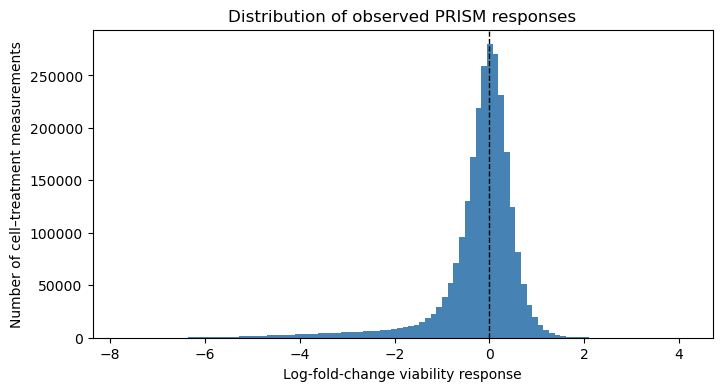

In [32]:
import matplotlib.pyplot as plt

# Flatten the matrix into observed measurements for this overview.
values = responses_verified.to_numpy().ravel()
values = values[pd.notna(values)]

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(values, bins=100, color="steelblue", edgecolor="none")
ax.axvline(0, color="black", linestyle="--", linewidth=1)

ax.set(
    title="Distribution of observed PRISM responses",
    xlabel="Log-fold-change viability response",
    ylabel="Number of cell–treatment measurements",
)

plt.show()


Responses cluster near zero with a pronounced negative tail. Because this distribution combines all treatments, I next examine treatment-level response patterns.

In [33]:
treatment_summary = pd.DataFrame({
    "n_measured": responses_verified.count(),
    "median_response": responses_verified.median(),
    "q10": responses_verified.quantile(0.10),
    "q90": responses_verified.quantile(0.90),
})

treatment_summary["response_spread"] = (
    treatment_summary["q90"] - treatment_summary["q10"]
)

display(
    treatment_summary.sort_values("median_response").head(10)
)

display(
    treatment_summary.sort_values("response_spread", ascending=False).head(10)
)


,n_measured,median_response,q10,q90,response_spread
BRD-K61397605-001-03-4::2.5::HTS,560,-4.432454,-6.069124,-2.745455,3.323669
BRD-K78659596-001-03-9::2.5::HTS,554,-4.306550,-5.800106,-2.731502,3.068604
BRD-A66419424-001-02-4::2.5::HTS,554,-4.207796,-5.754825,-2.538331,3.216494
BRD-K99475619-001-01-2::2.5::HTS,548,-4.200724,-5.859215,-2.477872,3.381342
BRD-K40331046-305-01-5::2.5::HTS,561,-4.176318,-5.808697,-2.213745,3.594952
BRD-K88510285-001-11-1::2.5::HTS,561,-4.171768,-5.738399,-2.613078,3.125321
BRD-K51911221-001-01-2::2.5::HTS,564,-4.156542,-5.774491,-2.429459,3.345032
BRD-K69650333-003-14-0::2.5::HTS,556,-4.154443,-5.632363,-2.400179,3.232184
BRD-K76674262-001-03-3::2.5::HTS,564,-4.150275,-5.828568,-2.431291,3.397277
BRD-K92093830-003-30-8::2.5::HTS,561,-4.117382,-5.746311,-2.067960,3.678350


,n_measured,median_response,q10,q90,response_spread
BRD-K66296774-236-11-3::2.63::HTS,541,-2.049995,-3.984564,0.455427,4.439991
BRD-K22134346-001-24-9::2.42::HTS,530,-0.974480,-3.250591,1.124531,4.375122
BRD-K96631475-001-02-4::2.43::HTS,530,-0.877953,-3.095011,1.272449,4.367460
BRD-K75958547-238-01-0::2.5::HTS,562,-0.755417,-3.154569,1.209727,4.364296
BRD-K41213548-001-02-0::2.5::HTS,548,-2.228847,-4.136194,0.184614,4.320808
BRD-K00317371-001-06-1::2.4::HTS,530,-1.268616,-3.714939,0.489713,4.204652
BRD-K96259238-001-01-4::2.5::HTS,561,-1.889229,-4.196484,-0.016250,4.180234
BRD-K13167095-001-02-9::2.5::HTS,564,-3.461594,-5.171494,-1.025540,4.145954
BRD-K58770988-001-01-8::2.5::HTS,561,-2.242594,-4.240674,-0.163120,4.077554
BRD-K02407574-001-09-7::2.5::HTS,564,-2.009209,-4.008516,-0.024568,3.983948


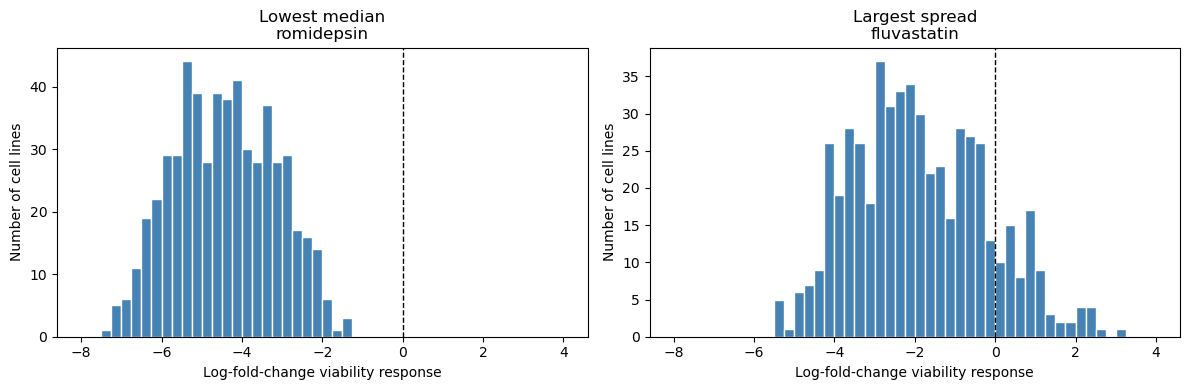

In [34]:
treatments = pd.read_csv(
    "../data/raw/primary-screen-replicate-collapsed-treatment-info.csv"
)

treatment_details = treatment_summary.join(
    treatments.set_index("column_name")[["name", "dose", "moa"]],
    how="left",
    validate="one_to_one",
)

selected = {
    "Lowest median": treatment_details["median_response"].idxmin(),
    "Largest spread": treatment_details["response_spread"].idxmax(),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

# Identical bin boundaries make the shapes easier to compare.
bins = [
    -8 + i * 0.25
    for i in range(49)
]

for ax, (label, treatment_id) in zip(axes, selected.items()):
    data = responses_verified[treatment_id].dropna()
    name = treatment_details.loc[treatment_id, "name"]

    ax.hist(data, bins=bins, color="steelblue", edgecolor="white")
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set(
        title=f"{label}\n{name}",
        xlabel="Log-fold-change viability response",
        ylabel="Number of cell lines",
    )

plt.tight_layout()
plt.show()

Romidepsin responses were consistently negative across measured cell lines,
whereas fluvastatin showed a broader range spanning negative and positive
values. These selected examples motivate investigating cell-line differences,
but do not establish the source of response variation.

In [35]:
cell_summary = pd.DataFrame({
    "n_measured": responses_verified.count(axis=1),
    "median_response": responses_verified.median(axis=1),
    "q10": responses_verified.quantile(0.10, axis=1),
    "q90": responses_verified.quantile(0.90, axis=1),
})

cell_summary["response_spread"] = (
    cell_summary["q90"] - cell_summary["q10"]
)

display(cell_summary.sort_values("median_response").head(10))
display(cell_summary.sort_values("response_spread", ascending=False).head(10))


,n_measured,median_response,q10,q90,response_spread
cell_id,,,,,
ACH-000051,1552,-0.398956,-1.643456,0.849030,2.492485
ACH-000446,1905,-0.355233,-1.666758,0.695716,2.362473
ACH-000269,2402,-0.323540,-1.638354,0.910840,2.549194
ACH-000756,4685,-0.212442,-1.278099,0.430800,1.708899
ACH-000222,4686,-0.206507,-1.135892,0.210143,1.346034
ACH-000123,4676,-0.202396,-1.252676,0.458235,1.710910
ACH-000418,4673,-0.200395,-1.300790,0.801154,2.101945
ACH-000940,4685,-0.196791,-1.600694,0.270540,1.871233
ACH-000430,4683,-0.194388,-1.539510,0.592663,2.132173


,n_measured,median_response,q10,q90,response_spread
cell_id,,,,,
ACH-000269,2402,-0.323540,-1.638354,0.910840,2.549194
ACH-000051,1552,-0.398956,-1.643456,0.849030,2.492485
ACH-000446,1905,-0.355233,-1.666758,0.695716,2.362473
ACH-000847,4684,0.255090,-1.273805,1.074986,2.348791
ACH-001099,4334,-0.185026,-1.460581,0.840025,2.300606
ACH-000139,4341,-0.063497,-1.382937,0.816641,2.199578
ACH-000163,4140,0.022511,-1.321749,0.859800,2.181549
ACH-000958,1482,-0.092600,-1.078218,1.066211,2.144430
ACH-000686,3708,-0.021073,-1.246715,0.890597,2.137312


Selected treatments showed substantial variation across cell lines. However,
these extreme examples do not establish whether treatment or cell-line
identity is more predictive. Several extreme cell-line summaries also have
low coverage, which may affect comparisons.

In [36]:
spread_comparison = pd.DataFrame({
    "Across cell lines, within each treatment":
        treatment_summary["response_spread"].describe(),
    "Across treatments, within each cell line":
        cell_summary["response_spread"].describe(),
})

display(spread_comparison)


,"Across cell lines, within each treatment","Across treatments, within each cell line"
count,4686.000000,568.000000
mean,1.211326,1.487493
std,0.680802,0.257061
min,0.615624,0.955955
25%,0.860247,1.312528
50%,0.950432,1.442014
75%,1.166014,1.626531
max,4.439991,2.549194


The median response spread (q90 − q10) was 0.95 across cell lines within
treatments and 1.44 across treatments within cell lines. Treatment spreads
were more heterogeneous, with a small subset showing much larger variation.
These summaries motivate treatment-specific baselines and investigating
whether cell-line features explain additional response differences.
